# Previsão de Churn em Operadora de Telecomunicações

C318 – Fundamentos de Machine Learning (Inatel). Escopo e decisões: [`BACKLOG.md`](BACKLOG.md) e [`DECISION_LOG.md`](DECISION_LOG.md).

## 1. Dados e limpeza

- `customerID` é removido, pois é só um identificador.
- `TotalCharges` vem como texto; os 11 brancos são clientes com `tenure = 0` (ainda não pagaram nada) e recebem 0 (D-08).
- `Churn` vira 0/1 (1 = cancelou).
- **Não** padronizamos `SeniorCitizen` nem fundimos "No internet service" com "No": o one-hot encoding já trata essas colunas sem perda (D-09).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42                      # mesma semente em todo o projeto
os.makedirs('figures', exist_ok=True)  # destino das figuras usadas nos slides

In [2]:
df = pd.read_csv('data/Telco-Customer-Churn.csv')
df = df.drop(columns='customerID')
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# TotalCharges vem como texto; os brancos (" ") viram NaN na conversão
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
nulos = df['TotalCharges'].isna()
n_nulos = nulos.sum()
tenure_dos_nulos = df.loc[nulos, 'tenure']
df['TotalCharges'] = df['TotalCharges'].fillna(0)  # D-08: cliente novo, ainda não pagou

df['Churn'] = (df['Churn'] == 'Yes').astype(int)   # alvo binário: 1 = cancelou

In [4]:
# Checagens de controle (D-07)
assert len(df) == 7043, 'número de clientes inesperado'
assert n_nulos == 11, 'número de brancos em TotalCharges inesperado'
assert (tenure_dos_nulos == 0).all(), 'brancos deveriam ser só clientes novos'
assert 0.26 < df['Churn'].mean() < 0.27, 'taxa de churn fora do esperado'
print(f"Clientes: {len(df)} | Taxa de churn: {df['Churn'].mean():.1%}")

Clientes: 7043 | Taxa de churn: 26.5%


## 2. Análise exploratória

Objetivo: responder **"Por que cancelam?"** (pergunta 2) e **"Quem é o cliente de risco?"** (pergunta 3), verificando as 5 hipóteses da proposta. A linha tracejada nos gráficos é a taxa geral de churn.

In [5]:
taxa_geral = df['Churn'].mean()
print(f'Taxa geral de churn: {taxa_geral:.1%}')

Taxa geral de churn: 26.5%


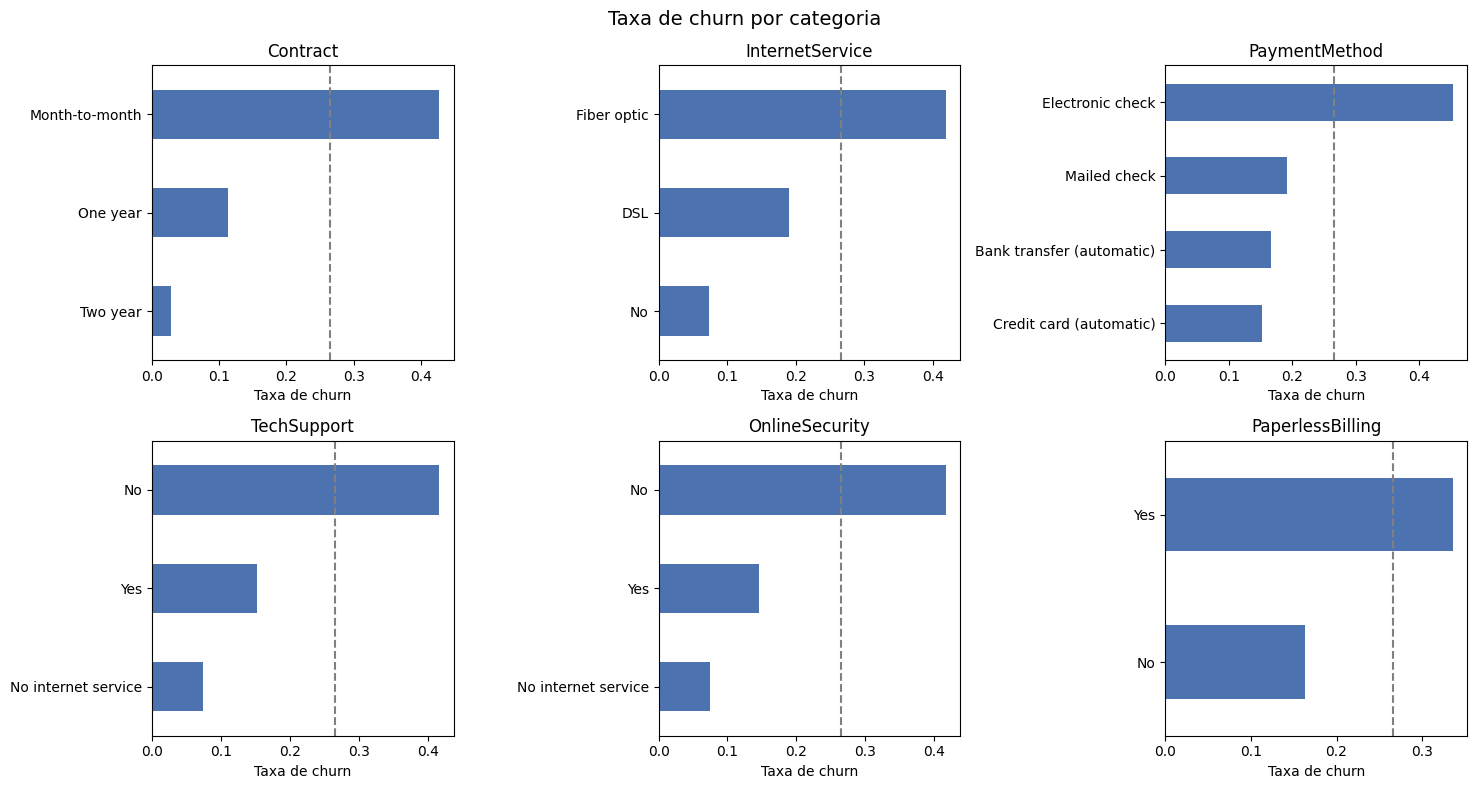

In [6]:
cats = ['Contract', 'InternetService', 'PaymentMethod',
        'TechSupport', 'OnlineSecurity', 'PaperlessBilling']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cats):
    df.groupby(col)['Churn'].mean().sort_values().plot.barh(ax=ax, color='#4C72B0')
    ax.axvline(taxa_geral, ls='--', color='gray')   # referência: média geral
    ax.set_title(col)
    ax.set_xlabel('Taxa de churn')
    ax.set_ylabel('')
fig.suptitle('Taxa de churn por categoria', fontsize=14)
fig.tight_layout()
fig.savefig('figures/01_churn_por_categoria.png', dpi=150, bbox_inches='tight')
plt.show()

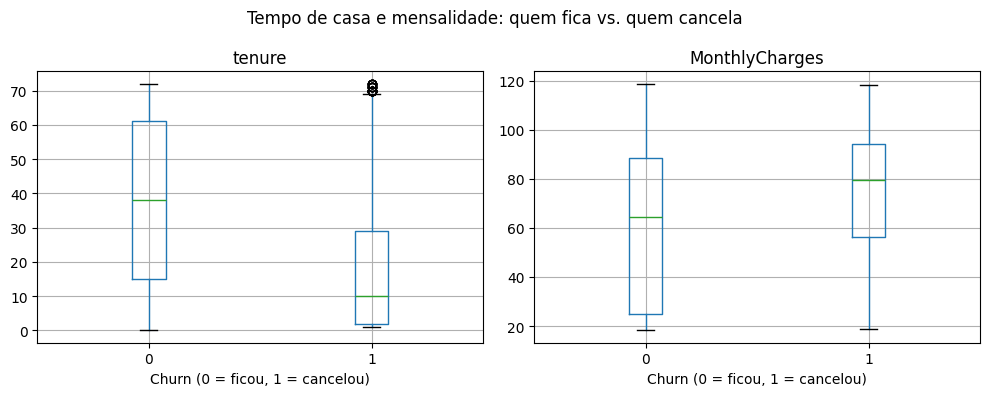

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ['tenure', 'MonthlyCharges']):
    df.boxplot(column=col, by='Churn', ax=ax)
    ax.set_title(col)
    ax.set_xlabel('Churn (0 = ficou, 1 = cancelou)')
fig.suptitle('Tempo de casa e mensalidade: quem fica vs. quem cancela')
fig.tight_layout()
fig.savefig('figures/02_numericas.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Perfil: cliente típico de cada classe
moda = lambda s: s.mode()[0]
perfil = df.groupby('Churn').agg(
    clientes=('Churn', 'size'),
    tenure=('tenure', 'mean'),
    MonthlyCharges=('MonthlyCharges', 'mean'),
    TotalCharges=('TotalCharges', 'mean'),
    Contract=('Contract', moda),
    InternetService=('InternetService', moda),
    PaymentMethod=('PaymentMethod', moda),
).round(1)
perfil

,clientes,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,PaymentMethod
Churn,,,,,,,
0,5174,37.6,61.3,2549.9,Month-to-month,DSL,Mailed check
1,1869,18.0,74.4,1531.8,Month-to-month,Fiber optic,Electronic check


In [9]:
# Hipóteses: churn do grupo de risco vs. grupo de comparação
def taxa(mask):
    return df.loc[mask, 'Churn'].mean()

hipoteses = {
    'H1 Contrato mensal':      (df.Contract == 'Month-to-month',        df.Contract != 'Month-to-month'),
    'H2 Cliente novo (≤12m)':  (df.tenure <= 12,                        df.tenure > 12),
    'H3 Fibra óptica':         (df.InternetService == 'Fiber optic',    df.InternetService == 'DSL'),
    'H4 Sem suporte técnico':  (df.TechSupport == 'No',                 df.TechSupport == 'Yes'),
    'H4 Sem segurança online': (df.OnlineSecurity == 'No',              df.OnlineSecurity == 'Yes'),
    'H5 Electronic check':     (df.PaymentMethod == 'Electronic check', df.PaymentMethod != 'Electronic check'),
}
tab = pd.DataFrame([(h, taxa(r), taxa(c)) for h, (r, c) in hipoteses.items()],
                   columns=['hipotese', 'churn_risco', 'churn_comparacao'])
tab['razao'] = tab.churn_risco / tab.churn_comparacao
tab['veredito'] = np.where(tab.razao >= 1.5, 'Confirmada', 'Não confirmada')
tab.style.format({'churn_risco': '{:.1%}', 'churn_comparacao': '{:.1%}', 'razao': '{:.1f}x'})

,hipotese,churn_risco,churn_comparacao,razao,veredito
0,H1 Contrato mensal,42.7%,6.8%,6.3x,Confirmada
1,H2 Cliente novo (≤12m),47.4%,17.1%,2.8x,Confirmada
2,H3 Fibra óptica,41.9%,19.0%,2.2x,Confirmada
3,H4 Sem suporte técnico,41.6%,15.2%,2.7x,Confirmada
4,H4 Sem segurança online,41.8%,14.6%,2.9x,Confirmada
5,H5 Electronic check,45.3%,17.1%,2.7x,Confirmada


### Leitura dos resultados

**As 5 hipóteses foram confirmadas.** Em todas, o grupo de risco tem 2 a 6 vezes o churn do grupo de comparação.

**Por que cancelam? (pergunta 2)**
- **Falta de compromisso contratual** é o fator mais forte. O contrato mensal tem 42,7% de churn, contra 6,8% nos contratos de 1 ou 2 anos (6,3×).
- **O primeiro ano é o período crítico.** Clientes com até 12 meses de casa cancelam 47,4%, contra 17,1% dos demais. Quem cancela tem mediana de 10 meses de casa, contra 38 de quem fica.
- **Fibra óptica** tem 41,9% de churn, contra 19,0% do DSL. É também o plano mais caro, e quem cancela paga em média mais (US\$ 74 contra US\$ 61). Os dados não permitem separar se a causa é preço ou qualidade.
- **Falta de serviços de proteção e suporte.** Sem suporte técnico, o churn é 41,6% (contra 15,2% com suporte). Sem segurança online, 41,8% (contra 14,6%).
- **Pagamento por *electronic check*** tem 45,3% de churn, contra 17,1% das outras formas. As formas automáticas (cartão e débito em conta) têm as menores taxas.
- Observado sem hipótese prévia: clientes com **fatura digital** cancelam o dobro (33,6% contra 16,3%).

**Quem é o cliente de risco? (pergunta 3)**
Contrato mensal, no primeiro ano de casa, internet de fibra, mensalidade acima da média, pagamento por *electronic check* e sem serviços de suporte ou segurança. O contrato mensal aparece como moda nas duas classes porque é o mais comum na base (55% dos clientes). A diferença entre as classes está na **taxa**, não na moda.

**Cuidados:**
- São **associações, não causas**, e os fatores se sobrepõem (por exemplo, clientes novos tendem a estar no contrato mensal). A seção 3 avalia o peso conjunto deles no modelo.
- `TotalCharges` é basicamente `tenure × MonthlyCharges` (correlação de 0,83 com `tenure`) e não traz informação nova (D-11). A coluna é mantida no modelo. Já `MonthlyCharges` sai do modelo, por ser redundante com os serviços contratados (ver seção 3 e D-30).

## 3. Modelagem

Objetivo: responder **"Quem vai cancelar?"** (pergunta 1).

- Treino/teste 80/20 estratificado. O teste só é usado na avaliação do modelo final.
- `MonthlyCharges` **não entra no modelo**: ela é praticamente a soma dos serviços contratados, e mantê-la junto com eles distorce os coeficientes (multicolinearidade, D-30). A informação continua disponível pelas colunas de serviço.
- Um único pré-processamento dentro do pipeline: one-hot nas categóricas e padronização nas numéricas. Por estar no pipeline, ele é aprendido só com os dados de treino de cada fold (D-15).
- 3 modelos com `class_weight='balanced'` para compensar o desbalanceamento (D-12, D-14), ajustados por `GridSearchCV` com 5 folds estratificados, otimizando ROC-AUC (D-16).

In [10]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             f1_score, accuracy_score, ConfusionMatrixDisplay)

In [11]:
# MonthlyCharges fica fora: é a soma dos serviços contratados (R² = 0,9988) e distorce os coeficientes (D-30)
X, y = df.drop(columns=['Churn', 'MonthlyCharges']), df['Churn']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

num = ['tenure', 'TotalCharges']
cat = [c for c in X.columns if c not in num]
pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat),
                         ('num', StandardScaler(), num)])

print(f'Treino: {len(X_train)} clientes ({y_train.mean():.1%} churn) | '
      f'Teste: {len(X_test)} clientes ({y_test.mean():.1%} churn)')

Treino: 5634 clientes (26.5% churn) | Teste: 1409 clientes (26.5% churn)


In [12]:
modelos = {
    'Regressão Logística': (LogisticRegression(class_weight='balanced', max_iter=1000),
                            {'clf__C': [0.01, 0.1, 1, 10]}),
    'Árvore de Decisão':   (DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
                            {'clf__max_depth': [3, 5, 8], 'clf__min_samples_leaf': [1, 20, 50]}),
    'Random Forest':       (RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                                   n_jobs=-1, random_state=RANDOM_STATE),
                            {'clf__max_depth': [None, 8, 12], 'clf__min_samples_leaf': [1, 5]}),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

buscas = {}
for nome, (clf, grade) in modelos.items():
    busca = GridSearchCV(Pipeline([('pre', pre), ('clf', clf)]), grade,
                         cv=cv, scoring='roc_auc', n_jobs=-1)
    buscas[nome] = busca.fit(X_train, y_train)

comparacao = pd.DataFrame({
    nome: {'auc_cv': b.best_score_,
           'desvio': b.cv_results_['std_test_score'][b.best_index_],
           'melhores_parametros': {k.replace('clf__', ''): v for k, v in b.best_params_.items()}}
    for nome, b in buscas.items()}).T.sort_values('auc_cv', ascending=False)
comparacao

,auc_cv,desvio,melhores_parametros
Random Forest,0.84668,0.009471,"{'max_depth': 8, 'min_samples_leaf': 5}"
Regressão Logística,0.845853,0.012375,{'C': 10}
Árvore de Decisão,0.832347,0.011875,"{'max_depth': 5, 'min_samples_leaf': 50}"


In [13]:
# Seleção (D-16): maior AUC, mas a Regressão Logística fica se a diferença for < 0,01
melhor = comparacao['auc_cv'].astype(float).idxmax()
if comparacao.loc[melhor, 'auc_cv'] - comparacao.loc['Regressão Logística', 'auc_cv'] < 0.01:
    melhor = 'Regressão Logística'
modelo_final = buscas[melhor].best_estimator_
print(f'Modelo final: {melhor}')

Modelo final: Regressão Logística


In [14]:
# Avaliação única no teste, com limiar 0,5
proba_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= 0.5).astype(int)

metricas_teste = pd.Series({
    'ROC-AUC': roc_auc_score(y_test, proba_test),
    'Precisão (churn)': precision_score(y_test, pred_test),
    'Recall (churn)': recall_score(y_test, pred_test),
    'F1 (churn)': f1_score(y_test, pred_test),
    'Acurácia (referência)': accuracy_score(y_test, pred_test),
}).round(3)
metricas_teste

ROC-AUC                  0.842
Precisão (churn)         0.504
Recall (churn)           0.789
F1 (churn)               0.615
Acurácia (referência)    0.738
dtype: float64

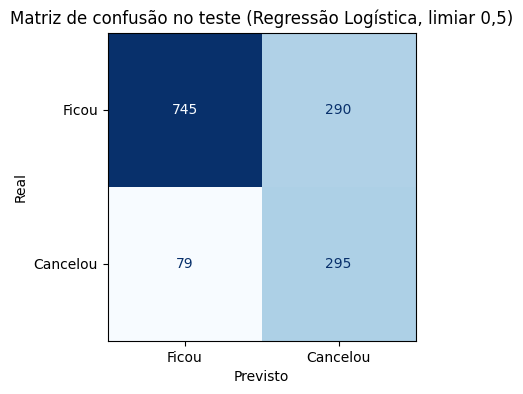

In [15]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=['Ficou', 'Cancelou'],
                                        cmap='Blues', colorbar=False, ax=ax)
ax.set_xlabel('Previsto')
ax.set_ylabel('Real')
ax.set_title(f'Matriz de confusão no teste ({melhor}, limiar 0,5)')
fig.savefig('figures/03_matriz_confusao.png', dpi=150, bbox_inches='tight')
plt.show()

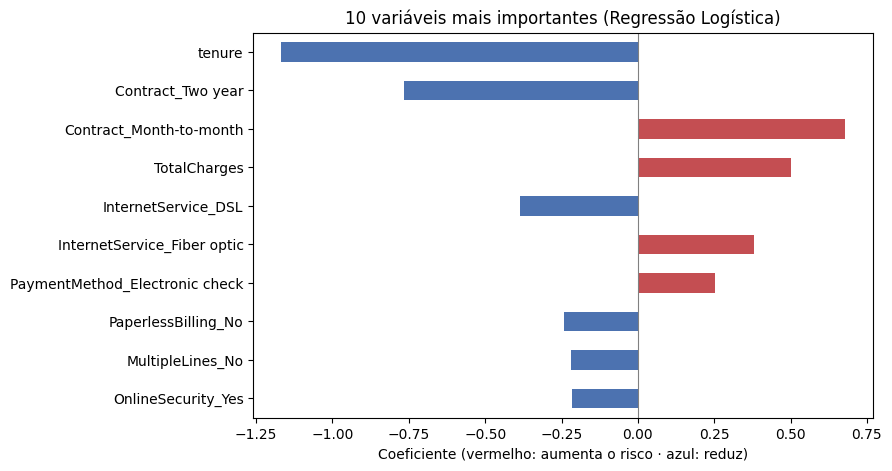

In [16]:
nomes = modelo_final['pre'].get_feature_names_out()
clf = modelo_final['clf']
eh_linear = hasattr(clf, 'coef_')
valores = clf.coef_[0] if eh_linear else clf.feature_importances_

importancia = (pd.Series(valores, index=[n.split('__', 1)[1] for n in nomes])
               .sort_values(key=abs, ascending=False).head(10)[::-1])

fig, ax = plt.subplots(figsize=(8, 5))
cores = np.where(importancia > 0, '#C44E52', '#4C72B0') if eh_linear else '#4C72B0'
importancia.plot.barh(ax=ax, color=cores)
ax.axvline(0, color='gray', lw=0.8)
ax.set_xlabel('Coeficiente (vermelho: aumenta o risco · azul: reduz)' if eh_linear
              else 'Importância')
ax.set_title(f'10 variáveis mais importantes ({melhor})')
fig.savefig('figures/04_importancia.png', dpi=150, bbox_inches='tight')
plt.show()

### Leitura dos resultados

**Comparação.** Random Forest (AUC 0,847) e Regressão Logística (0,846) empatam na prática: a diferença é menor que o desvio entre os folds. Pela regra de D-16, o modelo final é a **Regressão Logística**, que é mais simples de explicar. A Árvore de Decisão fica um pouco atrás (0,832).

**Desempenho no teste (limiar 0,5).** AUC de 0,842. O modelo encontra **295 dos 374 clientes que cancelaram** (recall de 0,79). Dos 585 clientes que ele sinaliza, metade de fato cancela (precisão de 0,50). A acurácia de 0,74 é praticamente igual aos 73,5% de quem "chuta" que ninguém cancela. Por isso ela não serve como métrica principal: o ganho do modelo está em encontrar os churns, e não em acertar mais no total. O limiar 0,5 é provisório. A seção 4 escolhe o limiar pelo ganho financeiro.

**Variáveis mais importantes.** Os coeficientes confirmam a EDA:
- **Reduzem o risco:** tempo de casa (o fator mais forte), contrato de 2 anos, internet DSL e segurança online.
- **Aumentam o risco:** contrato mensal, fibra óptica e pagamento por *electronic check*.
- `TotalCharges` positivo: para o mesmo tempo de casa, quem pagou mais no total tem um plano mais caro. É por aqui que o efeito do preço entra no modelo.

**Nota de modelagem (D-30).** Na primeira versão, `MonthlyCharges` aparecia como a variável mais importante, com sinal *negativo* ("mensalidade alta reduz o churn"), o oposto da EDA. A causa é **multicolinearidade**: a mensalidade é praticamente a soma dos serviços contratados (R² = 0,9988). Com a mesma informação duas vezes, o modelo dividiu o efeito de forma arbitrária entre mensalidade e serviços (um peso compensando o outro). As previsões continuavam boas, mas os coeficientes perdiam o significado. A solução foi retirar `MonthlyCharges` do modelo: o AUC não mudou (0,841 → 0,842) e os coeficientes passaram a fazer sentido. **Lição: prever bem não é o mesmo que explicar bem. Os coeficientes precisam ser conferidos contra a EDA.**

## 4. Limiar e impacto financeiro

Objetivo: responder **"Vale a pena agir?"** (pergunta 4), traduzindo o modelo em dinheiro.

Cada cliente contatado custa `CUSTO_CONTATO`. Se ele ia cancelar, há `TAXA_SUCESSO` de chance de retê-lo, o que preserva `MESES_VALOR` mensalidades. Clientes não contatados não alteram nada em relação a não fazer nada. Por isso:

**ganho = Σ (mensalidade × meses × taxa de sucesso dos churns contatados) − nº de contatados × custo**

O limiar que define quem é contatado é escolhido **só com o treino**, usando probabilidades *out-of-fold*. O teste é usado apenas para medir o resultado (D-19). Como o modelo usa `class_weight='balanced'`, as "probabilidades" servem para ordenar o risco, não como probabilidade literal. Por isso o limiar é escolhido pela curva de ganho, e não por fórmula.

In [17]:
# Premissas financeiras (D-20): mude aqui e reexecute o notebook
MESES_VALOR = 12      # valor do cliente retido = 12 mensalidades
TAXA_SUCESSO = 0.30   # 30% dos churns contatados acabam ficando
CUSTO_CONTATO = 50    # US$ por cliente contatado

In [18]:
from sklearn.model_selection import cross_val_predict

# MonthlyCharges saiu do modelo (D-30), mas continua no df para calcular o valor do cliente
monthly_train = df.loc[X_train.index, 'MonthlyCharges'].values
monthly_test = df.loc[X_test.index, 'MonthlyCharges'].values

def ganho(y, contatar, monthly, taxa=TAXA_SUCESSO, custo=CUSTO_CONTATO):
    """Ganho em US$ de contatar os clientes marcados em `contatar` (array booleano)."""
    vp = contatar & (y == 1)                      # churns que a campanha alcança
    return (monthly[vp] * MESES_VALOR * taxa).sum() - contatar.sum() * custo

# Probabilidades out-of-fold: cada cliente do treino é previsto por um modelo que não o viu
proba_oof = cross_val_predict(modelo_final, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
limiares = np.round(np.arange(0.05, 0.96, 0.01), 2)

def escolher_limiar(taxa=TAXA_SUCESSO, custo=CUSTO_CONTATO):
    """Limiar que maximiza o ganho no treino (OOF), e a curva de ganho completa."""
    ganhos = np.array([ganho(y_train.values, proba_oof >= t, monthly_train, taxa, custo)
                       for t in limiares])
    return limiares[ganhos.argmax()], ganhos

limiar_otimo, ganhos_oof = escolher_limiar()
print(f'Limiar ótimo (treino, OOF): {limiar_otimo:.2f}')

Limiar ótimo (treino, OOF): 0.47


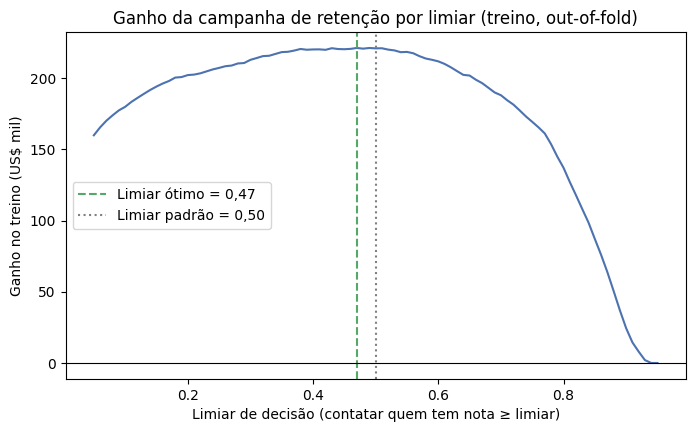

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(limiares, ganhos_oof / 1000, color='#4C72B0')
ax.axvline(limiar_otimo, color='#55A868', ls='--', label=f'Limiar ótimo = {limiar_otimo:.2f}'.replace('.', ','))
ax.axvline(0.5, color='gray', ls=':', label='Limiar padrão = 0,50')
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('Limiar de decisão (contatar quem tem nota ≥ limiar)')
ax.set_ylabel('Ganho no treino (US$ mil)')
ax.set_title('Ganho da campanha de retenção por limiar (treino, out-of-fold)')
ax.legend()
fig.savefig('figures/05_ganho_por_limiar.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
def cenarios(limiar, taxa=TAXA_SUCESSO, custo=CUSTO_CONTATO):
    """Compara as estratégias de campanha no TESTE."""
    y, n = y_test.values, len(y_test)
    linhas = {'Não fazer nada': dict(contatados=0, churns_alcancados=0, ganho=0.0,
                                      precisao=np.nan, recall=0.0)}
    estrategias = {'Contatar todos': np.ones(n, dtype=bool),
                   'Modelo (limiar 0,50)': proba_test >= 0.5,
                   'Modelo (limiar ótimo)': proba_test >= limiar}
    for nome, contatar in estrategias.items():
        vp = (contatar & (y == 1)).sum()
        linhas[nome] = dict(contatados=contatar.sum(), churns_alcancados=vp,
                            ganho=ganho(y, contatar, monthly_test, taxa, custo),
                            precisao=vp / contatar.sum(), recall=vp / y.sum())
    # Aleatória com o mesmo nº de contatos do modelo: valor esperado (sem depender de sorteio)
    k = linhas['Modelo (limiar ótimo)']['contatados']
    valor_churns = (monthly_test[y == 1] * MESES_VALOR * taxa).sum()
    linhas['Campanha aleatória (mesmo nº de contatos)'] = dict(
        contatados=k, churns_alcancados=k * y.mean(), ganho=k / n * valor_churns - k * custo,
        precisao=y.mean(), recall=k / n)
    ordem = ['Não fazer nada', 'Contatar todos', 'Campanha aleatória (mesmo nº de contatos)',
             'Modelo (limiar 0,50)', 'Modelo (limiar ótimo)']
    return pd.DataFrame(linhas).T.loc[ordem].astype(float)

tab_cenarios = cenarios(limiar_otimo)
tab_cenarios.style.format({'contatados': '{:,.0f}', 'churns_alcancados': '{:,.0f}',
                           'ganho': 'US$ {:,.0f}', 'precisao': '{:.1%}', 'recall': '{:.1%}'},
                          na_rep='—')

,contatados,churns_alcancados,ganho,precisao,recall
Não fazer nada,0,0,US$ 0,—,0.0%
Contatar todos,"1,409",374,"US$ 27,524",26.5%,100.0%
Campanha aleatória (mesmo nº de contatos),621,165,"US$ 12,131",26.5%,44.1%
"Modelo (limiar 0,50)",585,295,"US$ 51,901",50.4%,78.9%
Modelo (limiar ótimo),621,305,"US$ 51,477",49.1%,81.6%


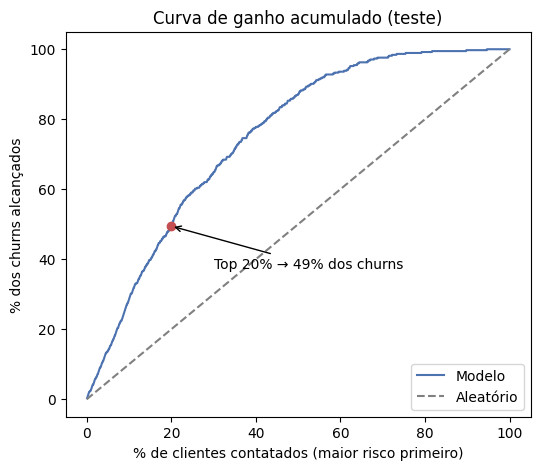

Contatando os 20% de maior risco, alcançamos 49.5% dos churns (2.5x o aleatório).


In [21]:
ordem = np.argsort(-proba_test)                         # do maior risco para o menor
captura = np.cumsum(y_test.values[ordem]) / y_test.sum()  # % dos churns alcançados
pct_contatados = np.arange(1, len(ordem) + 1) / len(ordem)

i20 = int(np.ceil(0.2 * len(ordem))) - 1
captura_20 = captura[i20]

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(pct_contatados * 100, captura * 100, color='#4C72B0', label='Modelo')
ax.plot([0, 100], [0, 100], color='gray', ls='--', label='Aleatório')
ax.scatter([20], [captura_20 * 100], color='#C44E52', zorder=3)
ax.annotate(f'Top 20% → {captura_20:.0%} dos churns', (20, captura_20 * 100),
            xytext=(30, captura_20 * 100 - 12), arrowprops=dict(arrowstyle='->'))
ax.set_xlabel('% de clientes contatados (maior risco primeiro)')
ax.set_ylabel('% dos churns alcançados')
ax.set_title('Curva de ganho acumulado (teste)')
ax.legend(loc='lower right')
fig.savefig('figures/06_curva_ganho_acumulado.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Contatando os 20% de maior risco, alcançamos {captura_20:.1%} dos churns '
      f'({captura_20 / 0.2:.1f}x o aleatório).')

### Sensibilidade às premissas (D-31)

As premissas financeiras são hipóteses. Para cada combinação de taxa de sucesso e custo por contato, o limiar é **reescolhido no treino** e o resultado é medido no teste.

In [22]:
linhas = []
for taxa in [0.15, 0.30, 0.45]:
    for custo in [25, 50, 100]:
        limiar, _ = escolher_limiar(taxa, custo)
        c = cenarios(limiar, taxa, custo)
        linhas.append({'taxa_sucesso': taxa, 'custo_contato': custo, 'limiar': limiar,
                       'contatados': c.loc['Modelo (limiar ótimo)', 'contatados'],
                       'ganho_modelo': c.loc['Modelo (limiar ótimo)', 'ganho'],
                       'ganho_aleatoria': c.loc['Campanha aleatória (mesmo nº de contatos)', 'ganho'],
                       'ganho_contatar_todos': c.loc['Contatar todos', 'ganho']})
sensibilidade = pd.DataFrame(linhas)
sensibilidade['modelo_vs_aleatoria'] = sensibilidade.ganho_modelo - sensibilidade.ganho_aleatoria
sensibilidade['modelo_vs_todos'] = sensibilidade.ganho_modelo - sensibilidade.ganho_contatar_todos
money = 'US$ {:,.0f}'
sensibilidade.style.format({'taxa_sucesso': '{:.0%}', 'custo_contato': 'US$ {:.0f}',
                            'limiar': '{:.2f}', 'contatados': '{:,.0f}',
                            'ganho_modelo': money, 'ganho_aleatoria': money,
                            'ganho_contatar_todos': money, 'modelo_vs_aleatoria': money,
                            'modelo_vs_todos': money}).hide(axis='index')

taxa_sucesso,custo_contato,limiar,contatados,ganho_modelo,ganho_aleatoria,ganho_contatar_todos,modelo_vs_aleatoria,modelo_vs_todos
15%,US$ 25,0.47,621,"US$ 25,739","US$ 6,065","US$ 13,762","US$ 19,673","US$ 11,977"
15%,US$ 50,0.67,409,"US$ 12,793","US$ -6,230","US$ -21,463","US$ 19,024","US$ 34,257"
15%,US$ 100,0.83,156,"US$ 1,839","US$ -10,176","US$ -91,913","US$ 12,016","US$ 93,753"
30%,US$ 25,0.18,949,"US$ 71,194","US$ 42,263","US$ 62,749","US$ 28,931","US$ 8,446"
30%,US$ 50,0.47,621,"US$ 51,477","US$ 12,131","US$ 27,524","US$ 39,347","US$ 23,954"
30%,US$ 100,0.67,409,"US$ 25,587","US$ -12,461","US$ -42,926","US$ 38,047","US$ 68,513"
45%,US$ 25,0.18,949,"US$ 118,654","US$ 75,257","US$ 111,735","US$ 43,397","US$ 6,918"
45%,US$ 50,0.35,756,"US$ 95,557","US$ 41,052","US$ 76,510","US$ 54,505","US$ 19,046"
45%,US$ 100,0.55,536,"US$ 63,632","US$ 2,305","US$ 6,060","US$ 61,327","US$ 57,572"


## 5. Conclusões

*Os números abaixo usam as premissas padrão (12 meses, 30% de sucesso, US\$ 50 por contato). Se a célula de parâmetros for alterada, este texto precisa ser revisto.*

**1. Quem vai cancelar?** É possível prever com desempenho útil: AUC de 0,84 no teste. No limiar escolhido, o modelo indica 621 dos 1.409 clientes do teste (44%) e alcança **305 dos 374 churns (82%)**, com precisão de 49%, quase o dobro da taxa base de 26,5%. Contatando apenas os **20% de maior risco, alcança cerca de 49% dos churns**, 2,5× mais que uma escolha aleatória.

**2. Por que cancelam?** Os principais fatores são falta de compromisso contratual (contrato mensal), estar no primeiro ano de casa, internet de fibra, pagamento por *electronic check* e ausência de segurança online ou suporte técnico. EDA e modelo concordam. O preço pesa por meio dos serviços contratados (D-30).

**3. Quem é o cliente de risco?** Contrato mensal, até 12 meses de casa, fibra óptica, mensalidade acima da média, *electronic check* e sem serviços de proteção.

**4. Vale a pena agir?** **Sim.**
- No teste, a campanha guiada pelo modelo gera **US\$ 51,5 mil**. Uma campanha aleatória com o mesmo número de contatos gera US\$ 12,1 mil: o modelo rende **4,2× mais**, um ganho adicional de US\$ 39 mil. Contatar todos gera US\$ 27,5 mil e usa 2,3× mais contatos.
- **A conclusão resiste às premissas.** O modelo vence a campanha aleatória e o contatar todos nas 9 combinações de taxa de sucesso e custo testadas. No cenário pessimista (15% de sucesso, US\$ 100 por contato), as alternativas dão **prejuízo**, e só o modelo continua positivo.
- **Escala:** o teste tem 1.409 clientes (20% da base). Uma extrapolação grosseira para os 7.043 clientes dá cerca de **US\$ 257 mil em 12 meses**, condicionada às premissas.

**Sobre o limiar.** A curva de ganho (Figura 5) é **plana entre cerca de 0,35 e 0,55**. O ótimo do treino (0,47) praticamente coincide com o padrão 0,50, e no teste o 0,50 rendeu até um pouco mais (US\$ 51,9 mil contra US\$ 51,5 mil, diferença menor que 1%, dentro do ruído). Com `class_weight='balanced'` e estas premissas, o limiar padrão já fica perto do ótimo: **o valor do modelo está em ordenar bem os clientes por risco.** O ajuste do limiar faz diferença quando as premissas mudam. Com contato barato (US\$ 25), o ótimo cai para 0,18 (contatar mais gente). Com contato caro e pouco sucesso, sobe para 0,83 (contatar só os casos mais certos). O limiar depende apenas da razão entre custo e taxa de sucesso: 15% com US\$ 25 equivale a 30% com US\$ 50.